<a href="https://colab.research.google.com/github/ujjwalkota2005-dotcom/UJWAL-20241CSE0613-DA-CA3/blob/main/UJWAL_K_U(20241CSE0613).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [68]:
cancer_data = load_breast_cancer()

X = pd.DataFrame(
    cancer_data.data,
    columns=cancer_data.feature_names
)

# The original target is 0 = malignant, 1 = benign.
# Convert it to 1 = malignant, 0 = benign.
y = pd.Series(
    (cancer_data.target == 0).astype(int),
    name="Malignant"
)

print("Dataset loaded successfully!")
display(X.head())

print("\nDataset shape:", X.shape)
print("\nTarget values:")
print(y.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

Dataset loaded successfully!


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset shape: (569, 30)

Target values:
Malignant
Benign       357
Malignant    212
Name: count, dtype: int64


In [69]:
print("Input features (X):")
display(X.head())

print("\nTarget variable (y):")
display(y.head())

print("\nNumber of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

Input features (X):


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target variable (y):


,Malignant
0,1
1,1
2,1
3,1
4,1



Number of input features: 30
Number of target values: 569


In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


In [71]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [72]:
y_pred = model.predict(X_test)

print("Actual values (0 = Benign, 1 = Malignant):")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values (0 = Benign, 1 = Malignant):
[0 1 0 1 0 0 1 0 0 0]

Predicted values:
[0 1 0 1 1 0 1 0 0 0]


In [73]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Positive (TP):", tp)
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)

Confusion matrix:
[[71  1]
 [ 3 39]]

True Positive (TP): 39
True Negative (TN): 71
False Positive (FP): 1
False Negative (FN): 3


In [74]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL EVALUATION METRICS")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

MODEL EVALUATION METRICS
Accuracy: 96.49 %
Precision: 97.5 %
Recall: 92.86 %
F1-Score: 95.12 %


In [75]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"]
    )
)

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



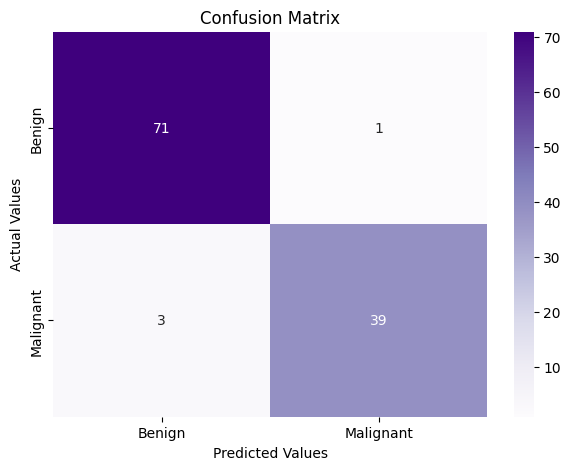

In [76]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")
plt.show()

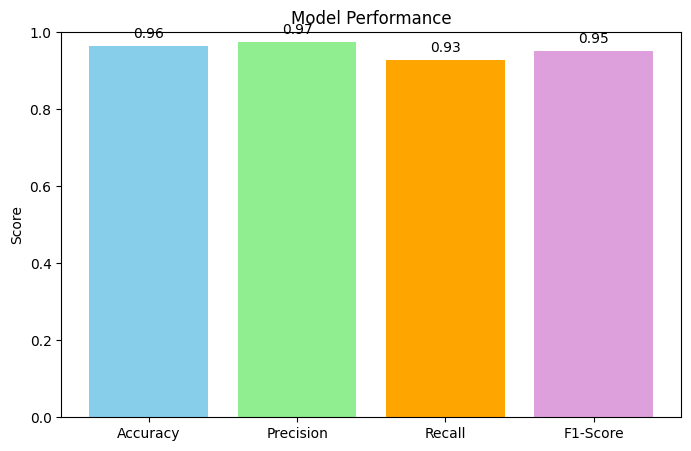

In [77]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(
    metrics.keys(),
    metrics.values(),
    color=["skyblue", "lightgreen", "orange", "plum"]
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Model Performance")

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f"{value:.2f}", ha="center")

plt.show()

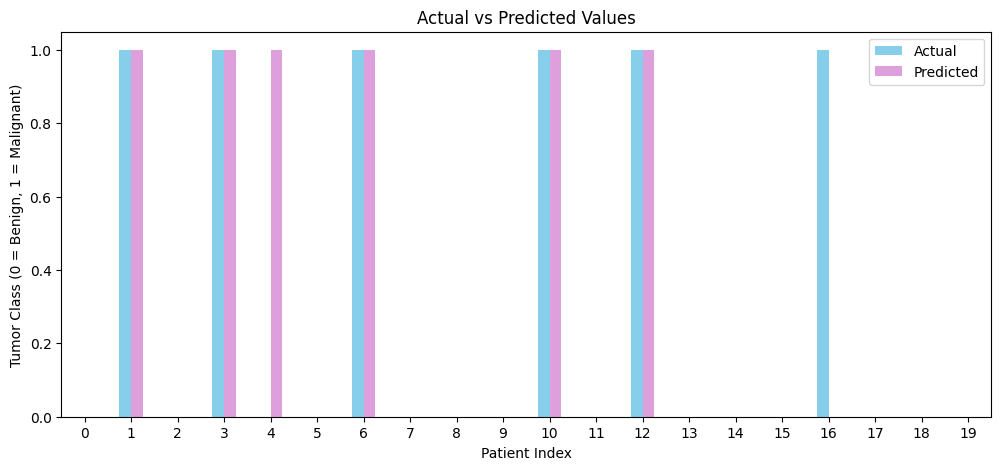

In [78]:
comparison = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": y_pred[:20]
})

comparison.plot(
    kind="bar",
    figsize=(12, 5),
    color=["skyblue", "plum"]
)

plt.title("Actual vs Predicted Values")
plt.xlabel("Patient Index")
plt.ylabel("Tumor Class (0 = Benign, 1 = Malignant)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

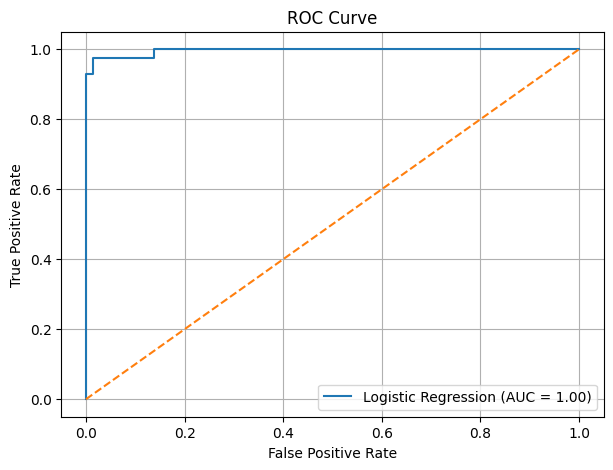

ROC-AUC Score: 0.996


In [79]:
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.2f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(auc, 3))

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'Diagnosis']


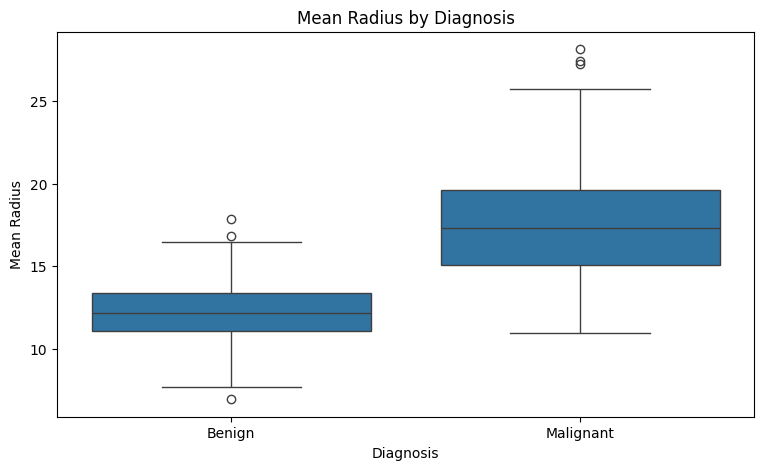

In [80]:
df = X.copy()
df["Diagnosis"] = y.map({0: "Benign", 1: "Malignant"})

print(df.columns.tolist())  # Check the available column names

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Diagnosis",
    y="mean radius",
    order=["Benign", "Malignant"]
)

plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.show()

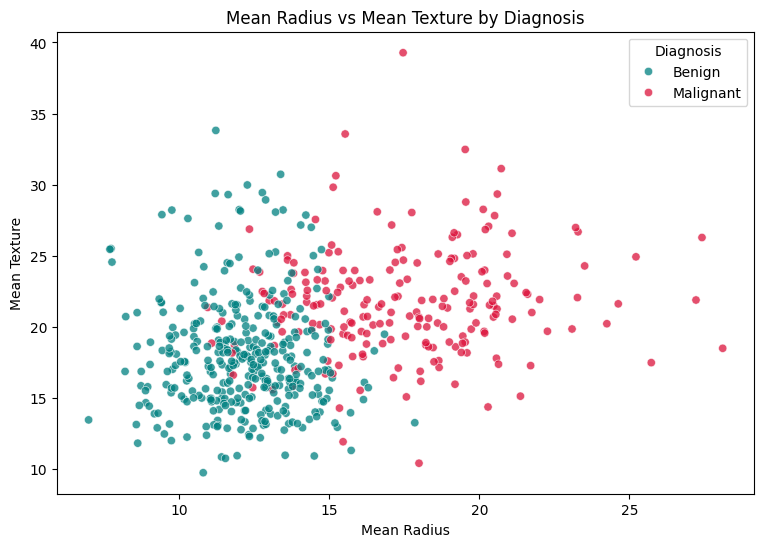

In [81]:
# Scatter plot: mean radius versus mean texture
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean texture",
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette={"Benign": "teal", "Malignant": "crimson"},
    alpha=0.75
)

plt.title("Mean Radius vs Mean Texture by Diagnosis")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.legend(title="Diagnosis")
plt.show()

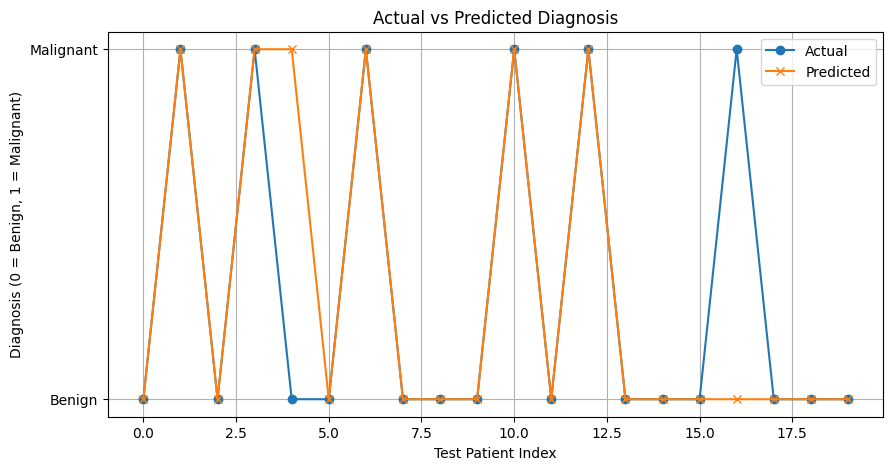

In [82]:
comparison = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": y_pred[:20]
})

plt.figure(figsize=(10, 5))

plt.plot(comparison.index, comparison["Actual"], marker="o", label="Actual")
plt.plot(comparison.index, comparison["Predicted"], marker="x", label="Predicted")

plt.title("Actual vs Predicted Diagnosis")
plt.xlabel("Test Patient Index")
plt.ylabel("Diagnosis (0 = Benign, 1 = Malignant)")
plt.yticks([0, 1], ["Benign", "Malignant"])
plt.legend()
plt.grid(True)
plt.show()